# Домашнее задание: подбор гиперпараметров бустинга и интерпретация модели с SHAP

**Ожидаемое время решения:** 1–1.5 часа.

## Задание

1. Постройте модель градиентного бустинга (LightGBM) на предложенном датасете, подобрав гиперпараметры с помощью Optuna. Исследуйте результаты подбора:
   1. Постройте **parallel coordinate plot** — какие гиперпараметры, судя по графику, можно зафиксировать (не тюнить), а какие критически важны?
   2. Постройте **contour plot** для пары наиболее важных гиперпараметров — хорошо ли подобрана сетка (границы) поиска, или оптимум упирается в край диапазона?
2. Исследуйте SHAP-значения обученной модели:
   1. По **beeswarm** и/или **bar plot** определите, какие признаки являются шумовыми (не влияют на предсказание).
   2. По **dependence plot** найдите интересные попарные взаимодействия признаков.

## Датасет

Мы работаем с синтетическим датасетом **кредитного скоринга** (предсказание дефолта заёмщика).

Формат сдачи: заполненный ноутбук `homework.ipynb`, который можно запустить целиком (Run All) без ошибок.

## 0. Импорт библиотек и генерация датасета

Ниже — готовый код для генерации датасета. Его не нужно менять, просто выполните ячейки.

In [3]:
# pip install lightgbm optuna plotly shap seaborn pandas numpy matplotlib scikit-learn

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import lightgbm as lgb

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

RANDOM_STATE = 42

df = pd.read_csv("credit_default_dataset.csv")
print(df.shape)
print(f"Доля дефолтов: {df['default'].mean():.3f}")
df.head()

(5000, 10)
Доля дефолтов: 0.329


,credit_score,debt_to_income,num_late_payments,employment_years,loan_amount,age,num_dependents,random_noise_1,random_noise_2,default
0,791.124188,0.392597,0,11.983732,30789.448624,40.644553,1,-0.459744,-0.302889,0
1,682.012577,0.048017,2,2.989243,16185.904729,63.539670,0,-0.101710,-0.477970,0
2,728.299039,0.220371,2,1.969566,47967.595997,39.928274,1,-0.101684,-0.676613,0
3,829.271456,0.573167,4,5.233681,33381.566076,62.364786,2,-1.101363,-0.439043,1
4,799.404639,0.451384,4,4.912667,9389.584941,32.648320,0,-0.950643,0.333650,0


### Разбиение на train/test

In [74]:
feature_cols = [c for c in df.columns if c != 'default']
X = df[feature_cols]
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)
X_train.shape, X_test.shape

((3500, 9), (1500, 9))

## 1. Подбор гиперпараметров LightGBM с помощью Optuna (4 балла)

**Задание:** напишите objective-функцию для Optuna, которая обучает `lgb.train` с подсказанными (`trial.suggest_*`) гиперпараметрами и возвращает AUC на валидационной выборке (`X_test`, `y_test`). Используйте early stopping.

Рекомендуемое пространство поиска (можно скорректировать):
- `num_leaves`: int, [10, 200]
- `learning_rate`: float, [0.001, 0.3], log scale
- `feature_fraction`: float, [0.5, 1.0]
- `bagging_fraction`: float, [0.5, 1.0]
- `bagging_freq`: int, [1, 10]
- `lambda_l1`: float, [1e-8, 10.0], log scale
- `lambda_l2`: float, [1e-8, 10.0], log scale

Запустите не менее 50 trials.

In [30]:
import optuna

train_data = lgb.Dataset(X_train, label=y_train)
valid_data = lgb.Dataset(X_test, label=y_test, reference=train_data)


def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'random_state': RANDOM_STATE,
        # TODO: задайте гиперпараметры через trial.suggest_*
        'num_leaves': trial.suggest_int('nl', 10, 200),       # TODO
        'learning_rate': trial.suggest_float('lr', 0.001, 0.3, log = True),    # TODO
        'feature_fraction': trial.suggest_float('ff', 0.5, 1, step=0.1), # TODO
        'bagging_fraction': trial.suggest_float('bf', 0.5, 1, step=0.1), # TODO
        'bagging_freq': trial.suggest_int('bfreq', 1, 10),     # TODO
        'lambda_l1': trial.suggest_float('ll1', 1e-8, 10, log = True),        # TODO
        'lambda_l2': trial.suggest_float('ll2', 1e-8, 10, log = True),        # TODO
    }

    # TODO: обучите модель с early stopping и верните AUC на валидации
    model = lgb.train(params=params, train_set=train_data, valid_sets=[valid_data], callbacks=[lgb.early_stopping(stopping_rounds=5)])
    auc = roc_auc_score(y_test, model.predict(X_test))
    return auc


# TODO: создайте study и запустите optimize (n_trials >= 50)
study = optuna.create_study(direction = 'maximize')
study.optimize(objective, n_trials=100)

print("Best params:", study.best_params)
print("Best AUC:", study.best_value)

[I 2026-08-17 11:42:21,496] A new study created in memory with name: no-name-8aba5e19-2dcb-4680-af9e-a7c78dac99bb
[I 2026-08-17 11:42:21,633] Trial 0 finished with value: 0.7990194399850137 and parameters: {'nl': 196, 'lr': 0.0705273747485078, 'ff': 0.9, 'bf': 0.5, 'bfreq': 10, 'll1': 0.0004629438315160144, 'll2': 1.0449993774765886e-05}. Best is trial 0 with value: 0.7990194399850137.


Training until validation scores don't improve for 5 rounds
Early stopping, best iteration is:
[12]	valid_0's auc: 0.799019
Training until validation scores don't improve for 5 rounds
Early stopping, best iteration is:
[7]	valid_0's auc: 0.798542


[I 2026-08-17 11:42:21,725] Trial 1 finished with value: 0.7985420514814151 and parameters: {'nl': 52, 'lr': 0.05154400830639196, 'ff': 1.0, 'bf': 0.8, 'bfreq': 9, 'll1': 0.0006884859390002433, 'll2': 0.006989662467225662}. Best is trial 0 with value: 0.7990194399850137.
[I 2026-08-17 11:42:21,832] Trial 2 finished with value: 0.8053262054059716 and parameters: {'nl': 126, 'lr': 0.005251711461603949, 'ff': 0.5, 'bf': 1.0, 'bfreq': 9, 'll1': 0.7639290916637684, 'll2': 0.4185229031770906}. Best is trial 2 with value: 0.8053262054059716.


Training until validation scores don't improve for 5 rounds
Early stopping, best iteration is:
[9]	valid_0's auc: 0.805326
Training until validation scores don't improve for 5 rounds


[I 2026-08-17 11:42:22,060] Trial 3 finished with value: 0.8070595083905562 and parameters: {'nl': 54, 'lr': 0.011314486868794599, 'ff': 0.9, 'bf': 0.5, 'bfreq': 6, 'll1': 9.907671907791262e-07, 'll2': 0.3285829046569555}. Best is trial 3 with value: 0.8070595083905562.
[I 2026-08-17 11:42:22,212] Trial 4 finished with value: 0.7907376558814465 and parameters: {'nl': 186, 'lr': 0.002204576969438107, 'ff': 0.8, 'bf': 1.0, 'bfreq': 8, 'll1': 3.563810269701872e-05, 'll2': 1.8178760744482202e-06}. Best is trial 3 with value: 0.8070595083905562.


...

Early stopping, best iteration is:
[22]	valid_0's auc: 0.807135
Training until validation scores don't improve for 5 rounds
Early stopping, best iteration is:
[10]	valid_0's auc: 0.815038
Training until validation scores don't improve for 5 rounds


[I 2026-08-17 11:42:43,988] Trial 98 finished with value: 0.8159989606224984 and parameters: {'nl': 34, 'lr': 0.02171999254999008, 'ff': 0.7, 'bf': 0.7, 'bfreq': 6, 'll1': 4.05225308268827e-08, 'll2': 0.11225598710965652}. Best is trial 72 with value: 0.8184020175203595.


Early stopping, best iteration is:
[21]	valid_0's auc: 0.815999
Training until validation scores don't improve for 5 rounds
Early stopping, best iteration is:
[21]	valid_0's auc: 0.815502


[I 2026-08-17 11:42:44,178] Trial 99 finished with value: 0.8155024362928064 and parameters: {'nl': 33, 'lr': 0.02154336766906775, 'ff': 0.7, 'bf': 0.7, 'bfreq': 6, 'll1': 3.442222945480754e-08, 'll2': 0.2108543941871566}. Best is trial 72 with value: 0.8184020175203595.


Best params: {'nl': 11, 'lr': 0.06137363935503316, 'ff': 0.6, 'bf': 0.7, 'bfreq': 8, 'll1': 7.892968184798275e-08, 'll2': 0.0004856521984383899}
Best AUC: 0.8184020175203595


### 1.1 Обучение финальной модели с лучшими параметрами

**Задание:** обучите LightGBM с параметрами `study.best_params` на полном train, сохраните модель в переменную `model_lgb` — она понадобится для SHAP-анализа далее.

In [138]:
best_params = study.best_params.copy()
rename_map = {
    'nl': 'num_leaves',
    'lr': 'learning_rate',
    'ff': 'feature_fraction',
    'bf': 'bagging_fraction',
    'bfreq': 'bagging_freq',
    'll1': 'lambda_l1',
    'll2': 'lambda_l2'
}
best_params = {rename_map.get(k, k): v for k, v in study.best_params.items()}
best_params.update({'objective': 'binary', 'metric': 'auc', 'verbosity': -1, 'random_state': RANDOM_STATE})

# TODO: обучите финальную модель model_lgb с best_params
model_lgb = lgb.train(params=best_params, train_set=train_data )

# TODO: посчитайте и выведите AUC на train и test
print(f"Train:\n{roc_auc_score(y_train, model_lgb.predict(X_train))}\nTest:\n{roc_auc_score(y_test, model_lgb.predict(X_test))}")

Train:
0.8918590585368161
Test:
0.8163041266912544


### 1.2 Parallel coordinate plot

**Задание:** постройте parallel coordinate plot для `study`. Изучите график и ответьте письменно (в markdown-ячейке ниже): какие гиперпараметры, судя по графику, слабо влияют на итоговый AUC и их можно было бы зафиксировать на разумном значении по умолчанию, чтобы сократить пространство поиска?

In [139]:
from optuna.visualization import plot_parallel_coordinate

# TODO: постройте parallel coordinate plot
fig = plot_parallel_coordinate(study)
fig.show()

**Ваш ответ:** Судя по графику, меньше всего влияют bfreq, ll1, ll2 потому что линии к ним и от них распределены +- равномерно, а значит, что вне зависимости от их значений модель может прийти к хорошей метрике, а значит, что их значения не особо влияют. Однако чтобы подтвердить наше утверждение рассмотрим ниже plot_param_importances, которое даст нам ещё больше информации о влиянии гиперпараметров.

### 1.3 Contour plot

**Задание:** выберите два гиперпараметра, которые (судя по `plot_param_importances`) сильнее всего влияют на метрику, и постройте для них contour plot. Ответьте: находится ли найденный оптимум внутри заданных границ поиска, или он «упирается» в край диапазона? Если упирается — как нужно было бы изменить границы поиска?

In [140]:
from optuna.visualization import plot_param_importances, plot_contour

# TODO: постройте plot_param_importances(study)
fig = plot_param_importances(study)
fig.show()
# TODO: выберите два наиболее важных гиперпараметра и постройте для них plot_contour(study, params=[...])
fig = plot_contour(study, params=['lr', 'nl'])
fig.show()

**Ваш ответ:** Как и предполагалось, названные 3 гиперпараметра меньше всего влияют на таргет. Более того, мы знаем, что оптимальный roc-auc - это $\approx 0.818$, по нашей легенде это самый тёмный участок графика, видно, что он находится внутри графика и не прижимается к его границам, так как такие значения лежат в правой нижней четверти и со всех сторон изолированы меньшими значениями: все тёмные участки находятся чуть правее и ниже середины, но если приблизить, то можно увидеть, что значение при движении к нижней границе (то есть при уменьшении nl, например, с 11 до 10) становится светлее, а со всех остальных сторон он находится с запасом вдали от границ, то есть он находится внутри границ. Если бы он упирался в левый край, то нам бы пришлось уменьшать lr, аналогично, если бы в правый, то пришлось увеличивать; если бы упирался в нижнюю границу, то пришлось бы делать nl меньше, но если бы упирался в верхнюю границу, то мы бы увеличивали nl.

## 2. Интерпретация модели с помощью SHAP (4 балла)

**Задание:** пересчитайте SHAP-значения для обученной модели `model_lgb` на тестовой выборке с помощью `shap.TreeExplainer`.

In [141]:
import shap

# TODO: создайте explainer
explainer = shap.TreeExplainer(model_lgb)

# TODO: посчитайте shap_values для X_test
shap_values = explainer.shap_values(X_test)

feature_names = feature_cols

c:\Users\temy2\AppData\Local\Programs\Python\Python310\lib\site-packages\shap\explainers\_tree.py:586: UserWarning:

LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray



### 2.1 Beeswarm / bar plot — поиск шумовых признаков

**Задание:** постройте beeswarm plot (`shap.summary_plot`) и bar plot (агрегированная важность). Определите, какие признаки являются шумовыми (SHAP value близок к нулю для всех наблюдений). Совпадает ли ваш список с тем, что вы ожидали, глядя на названия признаков?

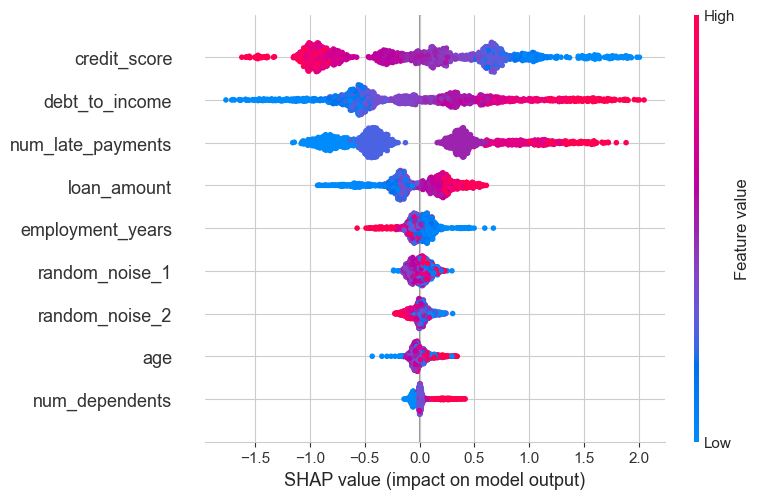

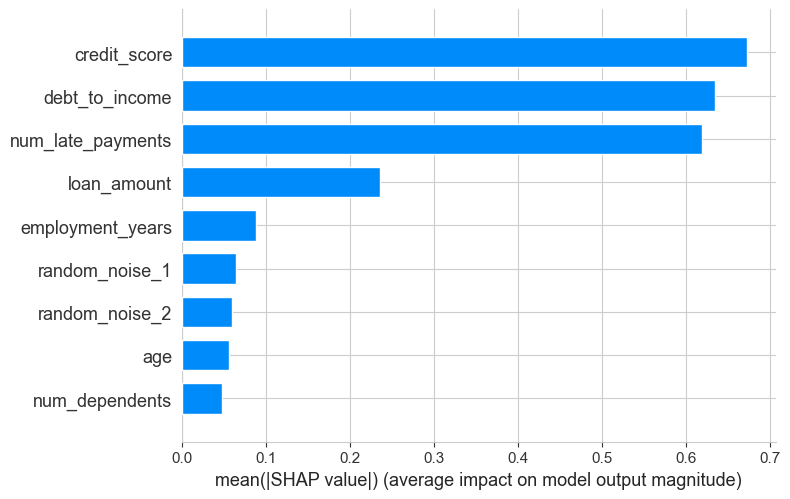

In [142]:
# TODO: постройте beeswarm plot
# shap.summary_plot(...)

shap.summary_plot(shap_values, X_test, feature_names=feature_cols, show = True)

# TODO: постройте bar plot (агрегированная важность)
# shap.summary_plot(..., plot_type='bar')

shap.summary_plot(shap_values, X_test, feature_names=feature_cols, show = True, plot_type='bar')

**Ваш ответ:** Судя по графику, 5 признаков с конца являются шумовыми: num_dependents, random_noise_2 (сюрприз-сюрприз), age, random_noise_1 (сюрприз-сюрприз), employment_years, так как их шапы ближе всего к нулю, кроме того, loan_amount делает существенный скачок относительно employment_years, причём этот скачок даже больше чем скачок employment_years относительно num_dependets, так что, кажется, ровно с этой фичи и начинаются информативные. Кроме того, в их классификации помогают две изначально шумовых фичи, понятно, что фичи, которые близки к ним по шапам не могут отличаться большей информативностью, чем шум. В целом список действительно близок к тому списку, который ожидаешь увидеть, смотря на названия, единственное, что мне казалось, что возраст должен быть информативнее обоих шумов, а оказалось, что ни одного, но понятно, что первые 4 сверху фичей напрямую относятся к тому, что мы предсказываем, а поэтому и несут больше всего информации, а вот все все остальные фичи уже не так прямо влияют на таргет, поэтому и близки к шуму.

### 2.2 Dependence plot — поиск попарных взаимодействий

**Задание:** постройте dependence plot для 2-3 наиболее важных признаков (по умолчанию SHAP сам подберёт цвет по признаку с наибольшим взаимодействием). Найдите признак, у которого зависимость SHAP value от значения самого признака выглядит по-разному в зависимости от цвета (значения второго признака) — это и есть взаимодействие. Дополнительно постройте dependence plot с явно заданным `interaction_index`, чтобы проверить гипотезу о конкретной паре признаков.

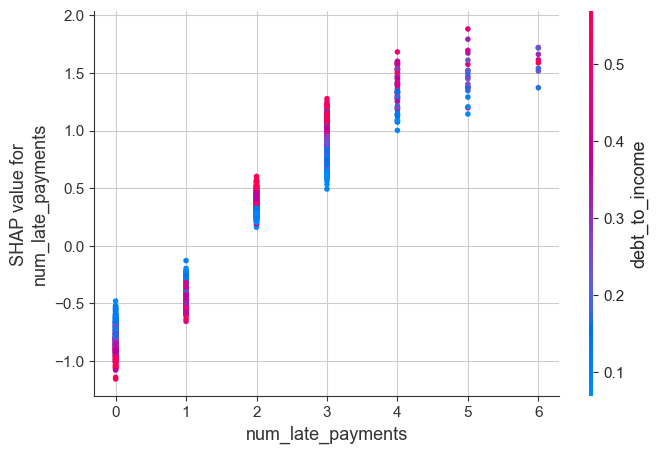

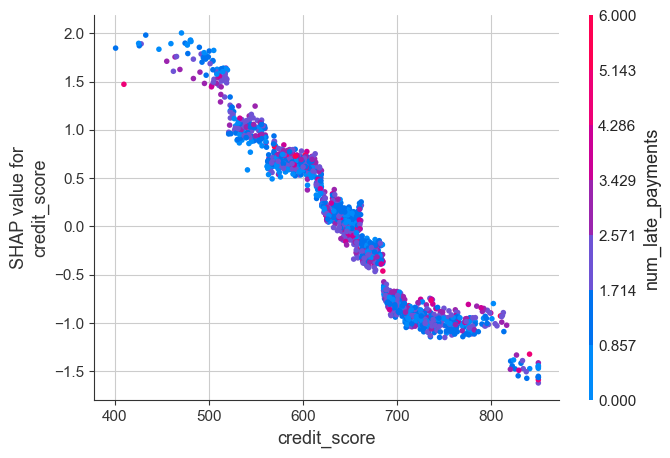

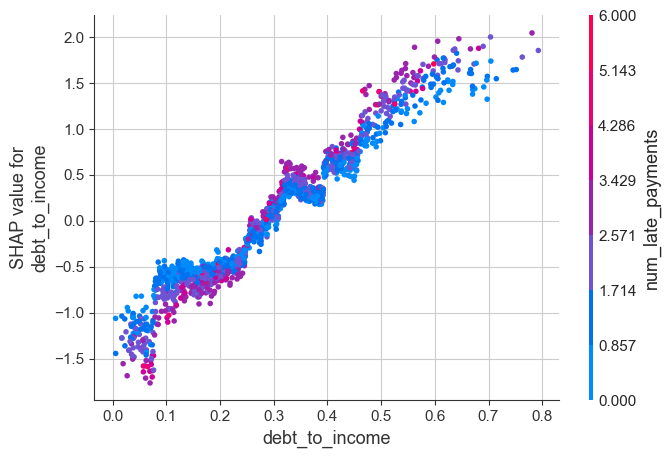

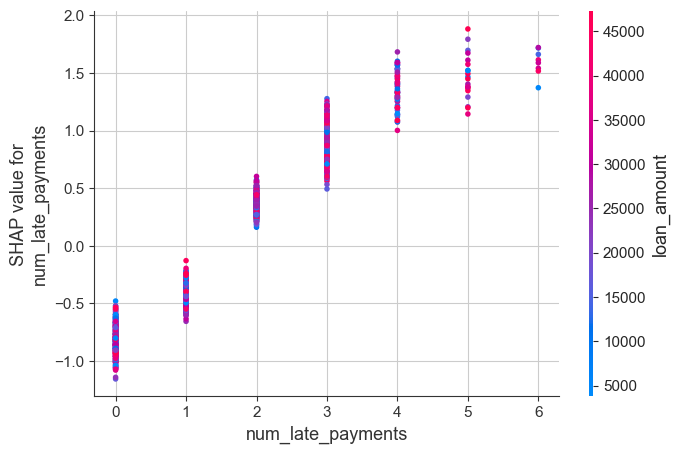

In [143]:
# TODO: постройте dependence plot для наиболее важного признака (по умолчанию)
# shap.dependence_plot(..., shap_values, X_test, feature_names=feature_names)
shap.dependence_plot('num_late_payments', shap_values, X_test, feature_names=feature_names, show = True)
shap.dependence_plot('credit_score', shap_values, X_test, feature_names=feature_names, show = True)
shap.dependence_plot('debt_to_income', shap_values, X_test, feature_names=feature_names, show = True)

# TODO: постройте dependence plot с явно заданным interaction_index для проверки конкретной гипотезы
# shap.dependence_plot(..., shap_values, X_test, feature_names=feature_names, interaction_index=...)
shap.dependence_plot('num_late_payments', shap_values, X_test, feature_names=feature_names, show = True, interaction_index=4)

**Ваш ответ:** Как и предполагалось, наиболее информативные по шапам фичи больше всего взаимодействуют друг с другом, причём даже по такой схеме:

```credit_score``` --> ```num_late_payments``` <--> ```debt_to_income```, где (1) --> (2) значит, что первый больше всего взаимодействует со вторым. Однако интересно ещё проверить, как взаимодействуют ```num_late_payments``` с ```loan_amount```, оказалось, что до какого-то момента размер долга сильно влияет на количество просрочек: чем в среднем больше размер долга, тем больше количество просрочек, однако на количестве просрочек = 6 оказалось, что в среднем у них относительно не очень большой размер долга, что возможно свидетельтсвует о том, что чем меньше размер долга, тем безответственнее заёмщики к нему относятся, потому что до этого момента сохранялась тендеция, что чем больше просрочек, тем больше и околокрасных (околомаксимальный размер долго) и тем больше визуально средний размер долга.

## 3. Итоговые выводы (3 балла)

Кратко (в виде bullet points) резюмируйте:
- Какие гиперпараметры оказались важны, а какие можно было не тюнить?
- Была ли сетка поиска гиперпараметров задана удачно?
- Какие признаки оказались шумовыми?
- Какое взаимодействие признаков вы обнаружили и согласуется ли оно с вашей интуицией о кредитном риске?

**Ваш ответ:**
- Важными оказались (по порядку):
num_leaves, learning_rate,  feature_fraction, bagging_fraction.
Можно было не тюнить:
lamda_l1, lambda_l2 точно, потому что у них очень маленькая важность; bagging_freq возможно стоит подбирать, потому что его важность меньше остальных, но не настолько маленькая, как у названных.
- Была, потому что оптимум лежал внутри диапазонов и не упирался в край, поэтому расширять их не было необходимости.
- Шумовые:
num_dependents, random_noise_2, age, random_noise_1, employment_years.
- В целом, все обнаруженные признаки вполне логично и согласуются с моим представлением: количество просрочек очевидно сильно связано с соотношением долга к доходам и наоборот; с другой стороны, кредитный скор тоже сильно связан с количеством просрочек; Интересное взаимодействие между количеством просрочек и размером долга, которое было описано выше, но тоже вполне логичное.
